In [1]:
import os
from background_functions import start_end_times, call_length_stats

txt_file = os.path.join(r"C:\Users\HP\Desktop\Skripsie data\26", "2023-04-26T07-55-05_000_00072.txt")

df, start_t, end_t = start_end_times(txt_file)
mean, max, min = call_length_stats(df)

print(f"Shortest call: {min:.3f} s")

print(f"Mean call: {mean:.3f} s")

print(f"Longest call: {max:.3f} s")

Shortest call: 0.097 s
Mean call: 0.246 s
Longest call: 0.645 s


In [2]:
import os
from background_functions import start_end_times, call_length_stats

txt_file = os.path.join(r"C:\Users\HP\Desktop\Skripsie data\29", "2023-04-29T10-28-41_000_00074.txt")

df, start_t, end_t = start_end_times(txt_file)
mean, max, min = call_length_stats(df)

print(f"Shortest call: {min:.3f} s")

print(f"Mean call: {mean:.3f} s")

print(f"Longest call: {max:.3f} s")


Shortest call: 0.096 s
Mean call: 0.178 s
Longest call: 0.512 s


In [3]:
import os
from background_functions import start_end_times, call_length_stats

txt_file = os.path.join(r"C:\Users\HP\Desktop\Skripsie data\22", "2023-04-22T17-13-01_000_00070.txt")

df, start_t, end_t = start_end_times(txt_file)
mean, max, min = call_length_stats(df)

print(f"Shortest call: {min:.3f} s")

print(f"Mean call: {mean:.3f} s")

print(f"Longest call: {max:.3f} s")


Shortest call: 0.225 s
Mean call: 0.573 s
Longest call: 2.584 s


In [5]:
import os
import csv
from collections import Counter

FILE_PATHS = [
    os.path.join(r"C:\Users\HP\Desktop\Skripsie data\22", "2023-04-22T17-13-01_000_00070.txt"),
    os.path.join(r"C:\Users\HP\Desktop\Skripsie data\26", "2023-04-26T07-55-05_000_00072.txt"),
    os.path.join(r"C:\Users\HP\Desktop\Skripsie data\29", "2023-04-29T10-28-41_000_00074.txt"),
]


def count_calls(path):
    counts = Counter()
    seen = set()

    with open(path, newline="", encoding="utf-8-sig") as f:
        reader = csv.DictReader(f, delimiter="\t")
        for row in reader:
            selection = row["Selection"].strip()
            call = row["Call"].strip()

            # Each selection appears twice (Waveform + Spectrogram),
            # so only count each selection number once.
            if selection in seen:
                continue
            seen.add(selection)

            counts[call] += 1

    return counts


def print_table(title, counts):
    print(title)
    print(f"{'Call type':<12}{'Count':>8}")
    print("-" * 20)
    for call, n in sorted(counts.items()):
        print(f"{call:<12}{n:>8}")
    print("-" * 20)
    print(f"{'TOTAL':<12}{sum(counts.values()):>8}")
    print()


def main():
    combined = Counter()

    for path in FILE_PATHS:
        counts = count_calls(path)
        print_table(f"File: {os.path.basename(path)}", counts)
        combined.update(counts)

    print_table("COMBINED (all files)", combined)


if __name__ == "__main__":
    main()

File: 2023-04-22T17-13-01_000_00070.txt
Call type      Count
--------------------
BT               171
MT               452
ST              1015
TD               164
--------------------
TOTAL           1802

File: 2023-04-26T07-55-05_000_00072.txt
Call type      Count
--------------------
BT                 9
MT                91
ST               242
--------------------
TOTAL            342

File: 2023-04-29T10-28-41_000_00074.txt
Call type      Count
--------------------
BT                11
MT                25
ST                32
--------------------
TOTAL             68

COMBINED (all files)
Call type      Count
--------------------
BT               191
MT               568
ST              1289
TD               164
--------------------
TOTAL           2212



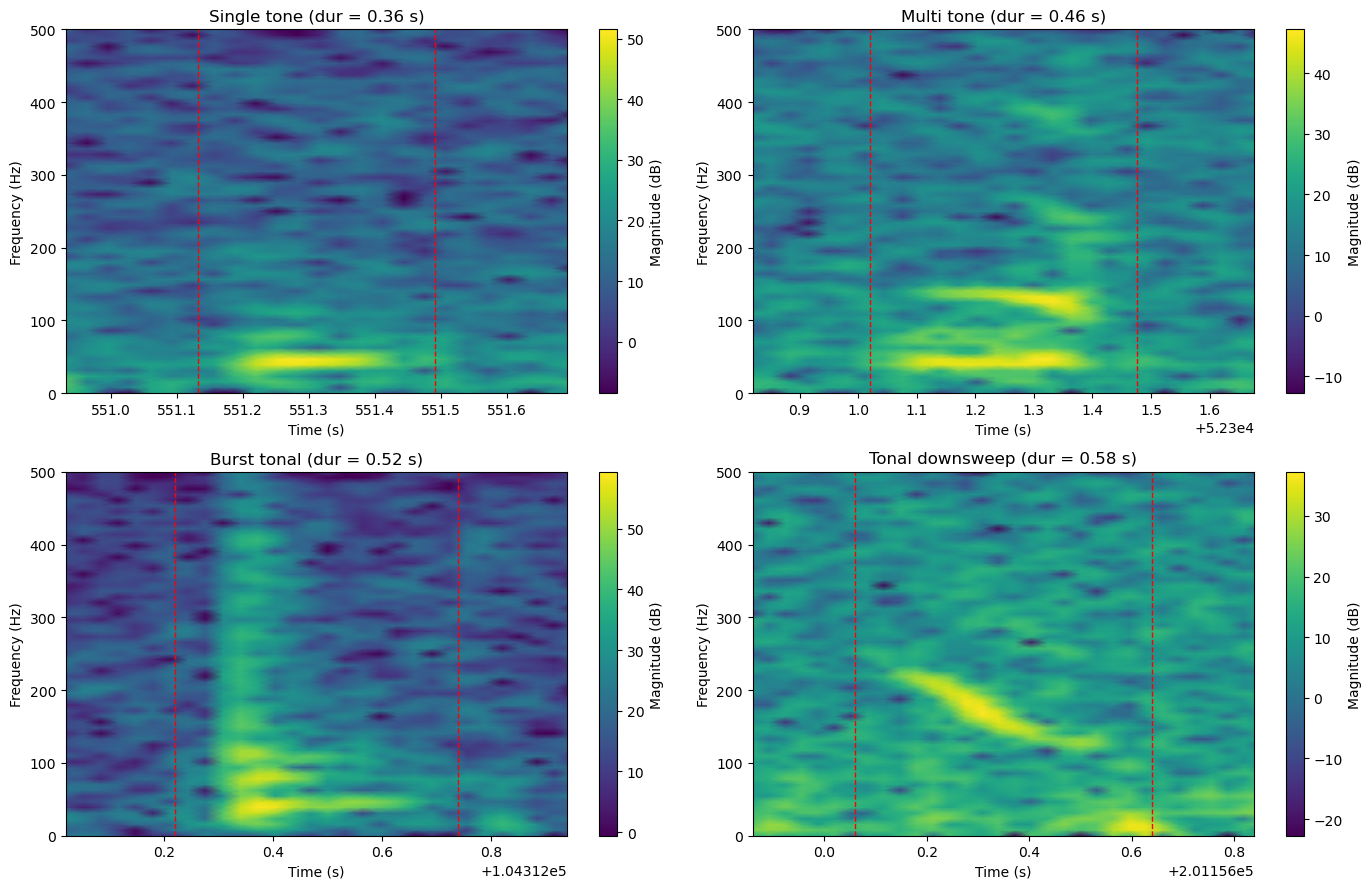

In [13]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy import signal

from calibration import load_entries
from feature import resample_audio
from testing import load_raven_selection_table

# ---------- settings ----------
fs_new = 1000
frame_dur = 0.128          # same STFT settings as your pipeline
overlap = 0.75
context = 1.0              # seconds of audio loaded either side (keeps STFT edges clean)
view_pad = 0.2             # seconds shown either side of the call (the zoom)
fmax_view = None           # e.g. 300 to also zoom the frequency axis; None = fs_new/2

idx = {
    "Single tone": 0,
    "Multi tone": 4,
    "Burst tonal": 8,      # change this to pick a different burst tonal template
}
td_idx = 2              # which tonal downsweep to show

DATA_29 = Path(r"C:\Users\HP\Desktop\Skripsie data\29")
RESULTS_29 = DATA_29 / "template_selections"

DATA_22 = Path(r"C:\Users\HP\Desktop\Skripsie data\22")
td_wav = DATA_22 / "20230422_171301.wav"
td_table = DATA_22 / "2023-04-22T17-13-01_000_00070.txt"

template_files = {
    "Single tone":  "20230429_Templates_20230429_102841_single_tone_templates.json",
    "Multi tone":   "20230429_Templates_20230429_102841_multi_tone_templates.json",
    "Burst tonal":  "20230429_Templates_20230429_102841_burst_tonal_templates.json",
}

def load_call_with_context(entry, context, fs_new):
    """Read the call plus `context` seconds either side, resampled to fs_new."""
    with sf.SoundFile(entry["wav_path"]) as f:
        f_s = f.samplerate
        total_s = f.frames / f_s
        seg_start = max(0.0, entry["start_time"] - context)
        seg_end = min(total_s, entry["end_time"] + context)
        f.seek(int(seg_start * f_s))
        segment = f.read(int((seg_end - seg_start) * f_s), dtype="int16")
    audio = resample_audio(segment, f_s, fs_new)
    return audio, seg_start

def compute_stft_db(audio, fs, frame_dur, overlap):
    nperseg = int(fs * frame_dur)
    f, t, Zxx = signal.stft(audio, fs=fs, nperseg=nperseg,
                            noverlap=int(nperseg * overlap), window="hamming")
    return f, t, 20 * np.log10(np.abs(Zxx) + 1e-10)

# ---------- collect one entry per call type ----------
examples = {}
for name, fname in template_files.items():
    examples[name] = load_entries(RESULTS_29 / fname)[idx[name]]

# tonal downsweep: pull from the Raven table
raven = load_raven_selection_table(td_table)
td_calls = [g for g in raven if g["label"] == "td"]
if not td_calls:
    raise ValueError(f"No 'td' labels found. Labels present: {sorted({g['label'] for g in raven})}")
td = td_calls[td_idx]
examples["Tonal downsweep"] = dict(wav_path=str(td_wav),
                                   start_time=td["start"],
                                   end_time=td["end"])

# ---------- plot ----------
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (name, entry) in zip(axes.flatten(), examples.items()):
    audio, seg_start = load_call_with_context(entry, context, fs_new)
    f, t, Zxx_db = compute_stft_db(audio, fs_new, frame_dur, overlap)
    t_abs = t + seg_start

    x_lo = entry["start_time"] - view_pad
    x_hi = entry["end_time"] + view_pad

    # colour range from the visible window only
    in_view = (t_abs >= x_lo) & (t_abs <= x_hi)
    vmax = Zxx_db[:, in_view].max()
    img = ax.pcolormesh(t_abs, f, Zxx_db, shading="gouraud",
                        cmap="viridis", vmin=vmax - 60, vmax=vmax)

    ax.axvline(entry["start_time"], color="red", linestyle="--", linewidth=1)
    ax.axvline(entry["end_time"], color="red", linestyle="--", linewidth=1)
    dur = entry["end_time"] - entry["start_time"]
    ax.set_title(f"{name} (dur = {dur:.2f} s)")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_xlim(x_lo, x_hi)
    ax.set_ylim(0, fmax_view or fs_new / 2)
    fig.colorbar(img, ax=ax, label="Magnitude (dB)")

plt.tight_layout()
plt.show()